# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [1]:
# importar librerías
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv') #completa el código
usage = pd.read_csv('/datasets/usage.csv') #completa el código

In [3]:


#mostrar las primeras 5 filas de plans
plans.head(5)



,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [4]:
# mostrar las primeras 5 filas de users

users.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [5]:
# mostrar las primeras 5 filas de usage
usage.head(5)

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [6]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [7]:
# inspección de plans con .info()

plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [8]:
# inspección de users con .info()
#City tiene valores nulos o faltantes
#churn_date tiene valores nulos o faltantes.
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [9]:
# inspección de usage con .info()
#date, duration y lenght tienen valores faltantes o nulos. 
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [10]:
# cantidad de nulos para users
print("users",users.isna().sum()) # Cantidad de valores nulos)
print("users", users.isna().mean()) # Proporción de valores nulos)

users user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64
users user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [11]:
# cantidad de nulos para usage
print ("usage", usage.isna(). sum())
print("usage", usage.isna().mean())

usage id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64
usage id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico al final del bloque. Incluye qué ves y que acción recomendarías para cada caso.

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).

Para el DF de USERS:
- City: 1/3 parte de los datos muestran nulos, al ser de tipo texto, no nos conviene tomar una decisión en automatico de eliminar, primero se debe investigar porque faltan los datos y despues imputar.
- Churn date: la gran mayoria de los datos son invalidos/nulos, pero no sería correcto inventar undato, en este caso dejar como nulos ya que el usuario sigue siendo un cliente.

Para el DF de USAGE:
- Date: Una muy pequeña parte del DF muestra nulos, sería revisarlos con un .info() brevemente y decidir si se pueden dejar como nulos, ya que imputar sería inventar un dato, en este caso.
- Duration: Casi la mitad de los datos estan nulos, al no ser una columna critica para el analisis, se podría ignorar o eliminar. 
- Lenght: Una cuarta parte del DF tiene nulos, al no ser una columna critica para el analisis recomiendo ignorar o eliminar.
 ---

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [12]:
# explorar columnas numéricas de users

users.describe()

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


FINDINGS: 
1. En la columna age tenemos un sentinel (-999). La edad minima de -999 es imposible, así que ese valor probablemente se uso como una flag para marcar datos faltantes o desconocidos. Se debe de reemplazar por NaN antes de correr analisis.
2. La media de age (33.74) podría estar sesgada, ya que la mediana (50%) es de 47. Tal vez el -999 este provocando que no concuerden, una vez corregido faltaría volver a revisar si se corrige.
3. La desviación estandar de age esta incorrecta, ya que no es posible que alguien llegue a la edad de 123 años. Probablemente haya un outlier distorcionando el STD e igual podría ser provocado por el sentinel.
4. La columna user_id no tiene una real interpretación analitica, porque es un número de identificador por cliente. 

In [13]:
# explorar columnas numéricas de usage

usage.describe()

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000



FINDINGS:
- Count deberia ser el mismo para todas las columnas, sin embargo duration y lenght tienen menos valores, por lo que nos dice que hay valores faltantes aqui. Duration tiene aprox 55% valores nulos y lenght 44%
- Los registros de llamadas con duración igual a cero pueden traducirse a llamadas canceladas o perdidas. También un posible error de registro.
- Un registro con length = 0 podría tratarse mas de un error de capura.
- La media de duration es mayor que la mediana (50%), podría tratarse de pocas llamadas de larga duración.
- El valor max de duration (120 mins) esta por muy encima del tercer cuartil (6.99 mins) lo que evidencia valores extremos que haran una cola larga en el histograma.
- El valor max de lenght (1490) también esta por encima del tercer cuartil (64), podría ser registros de consumo muy altos pero que dependen por evento, no son constantes.
- Las columnas id y user_id son identificadores y sus datos no son compatibles para analisis estadistico.

In [14]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']
users[columnas_user].describe()

,city,plan
count,3531,4000
unique,7,2
top,Bogotá,Basico
freq,808,2595


- La columna `city` tiene 3531 datos ingresados como validos. Se conforma de 7 categorias unicas, siendo "Bogota" la mas utilizada 808 veces.
- La columna `plan` tiene 4000 datos ingresados como validos. Se conforma de 2 categorias unicas, siendo "Básico" la mas utilizada 2595 veces.

In [15]:
# explorar columna categórica de usage
columnas_usage = ['type']
usage[columnas_usage].describe() # completa el código

,type
count,40000
unique,2
top,text
freq,22092


- La columna `type` tiene 4000 datos ingresados como validos. Se conforma de 2 categorias unicas, siendo "text" el mas utilizado 22092 veces.


---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- En la columna "city" existen 469 valores invalidos. Yo recomendaria revisar para ver si se trata de una falta ortografica o un mal ingreso, si es el caso imputar. Si falta el dato porque el usuario no lo ingreso, no se pueden inventar datos y lo recomendado sería corregir a NaN.

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [16]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date']) # completa el código

In [17]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date']) # completa el código

In [18]:
# Revisar los años presentes en `reg_date` de users
users['reg_date'].dt.year.unique()

array([2022, 2026, 2023, 2024])

En `reg_date`, hay fechas mal ingresadas, ya que solamente se cuentan con registros hasta el 2024 pero la función revela que hay datos con fechas del 2026, lo cual no es posible.

In [19]:
# Revisar los años presentes en `date` de usage
usage['date'].dt.year.unique()

array([2024.,   nan])

En `date`, se puede observar que solamente tenemos datos validos asociados al año 2024, probablemente habia valores invalidos que fueron cambiados por nan

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos): SI, en este caso mi decisión sería cambiarlos por "NaN" ya que imputarlos sería ingresar información no veridica.


---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [20]:
# Reemplazar -999 por la mediana de age
age_mediana = users.loc[users['age']!= - 999, 'age'].median()
users['age'] = users['age'].replace(-999,age_mediana)

# Verificar cambios
users['age'].describe()


count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [21]:
# Reemplazar ? por NA en city
users['city'] = users ['city'].replace("?", np.nan)

# Verificar cambios
users['city'].isna().sum()

565

In [22]:
# Marcar fechas futuras como NA para reg_date
users.loc[users['reg_date'].dt.year>=2026, 'reg_date'] = pd.NaT

# Verificar cambios
users['reg_date'].isna().sum()

40

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [23]:
# Verificación MAR en usage (Missing At Random) para duration
pd.crosstab(
    usage['type'],
    usage['duration'].isna(),
    normalize = 'index'
)


duration,False,True
type,,
call,1.000000,0.000000
text,0.000724,0.999276


In [24]:
# Verificación MAR en usage (Missing At Random) para length
pd.crosstab(
    usage['type'],
    usage['length'].isna(),
    normalize = 'index'
)

length,False,True
type,,
call,0.00067,0.99933
text,1.00000,0.00000


Haz doble clic aquíy escribe que tu diagnostico de nulos en `duration` y `length`

Con la verificación duration vs type, el resultado nos dice que los valores nulos de duration si dependen de la columna type. El total de los registros de call, tienen una duración registrada pero el 99.93% de los mensajes de texto tienen una duració nula y solo el 0.07% de los registros de text tienen datos de duración. Se confirma que son MAR. Mi recomendación es no imputar los nulos porque los NaN en duration para los registros del tipo text  SI tienen un significado y es que la duración no aplica. Sin embargo, si investigaría porque hay 0.07% de presencia de datos, no es consistente.

Con la verificación de lenght vs type, el resultado nos dice que los nulos si dependen de type. Todos los mensajes de texto tienen un valor en lenght, pero casi la totalidad de los registros de call tienen valores nulos. Mi recomendación es no imputar los valores nulos de lenght, porque esos nulos son esperados dada la naturaleza del evento.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [25]:

# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas


# Agrupar información por usuario
usage_agg = (
    usage.groupby('user_id')[['is_text', 'is_call', 'duration']]
    .sum()
    .reset_index()
)
# observar resultado
usage_agg.head(3)


,user_id,is_text,is_call,duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [26]:
# Renombrar columnas
usage_agg = usage_agg.rename(
    columns = {
        'is_text': 'cant_mensajes',
        'is_call': 'cant_llamadas',
        'duration': 'cant_minutos_llamada'
    }
)

# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [27]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(
    usage_agg,
    on='user_id',
    how='left'
    
)
user_profile.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,NaN,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [28]:
# Resumen estadístico de las columnas numéricas
columnas_numericas_user  = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']
user_profile [columnas_numericas_user].describe()

,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,3999.000000,3999.000000,3999.000000
mean,48.136000,5.524381,4.478120,23.317054
std,17.689919,2.358416,2.144238,18.168095
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.120000
50%,48.000000,5.000000,4.000000,19.780000
75%,63.000000,7.000000,6.000000,31.415000
max,79.000000,17.000000,15.000000,155.690000


In [29]:
# Distribución porcentual del tipo de plan
user_profile['plan'].value_counts(normalize = True)*100

Basico     64.875
Premium    35.125
Name: plan, dtype: float64

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

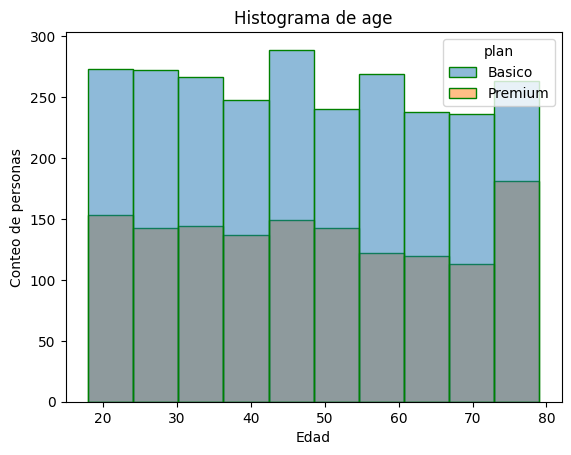

In [30]:
# Histograma para visualizar la edad (age)

sns.histplot(data=user_profile, x='age', hue= 'plan', bins= 10,color='skyblue', edgecolor= 'green')
#sns.histplot(user_profile['age'], bins= 10, color = 'skyblue', edgecolor = 'green') --> codigo sin comparativa de basico vs premium.
plt.title('Histograma de age')
plt.xlabel('Edad')
plt.ylabel('Conteo de personas')
plt.show()



💡Insights: 
- La columna age tiene una distribución simetrica ( no hay evidencias de sesgos) y tampoco hay valores atipicos.
- La edad minima esta alrededor de los 18-20 años y la máxima 75-79 años.
-  Es indiferente la edad de la persona para elegir el tipo de plan (básico vs premium), casi todos los grupos tienen una división igual entre los planes, a excepción de los mas grandes que preferien el servicio premium.

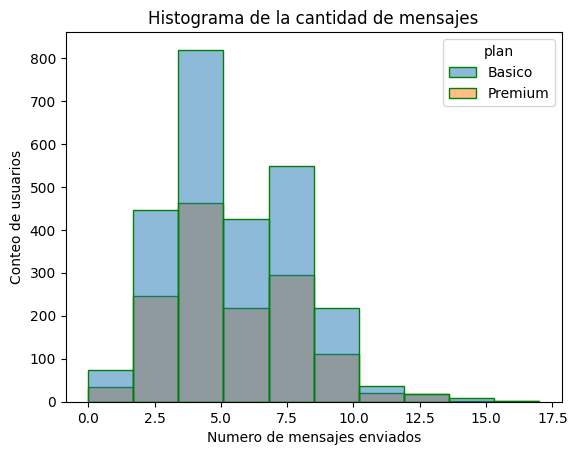

In [31]:
# Histograma para visualizar la cant_mensajes
sns.histplot(data=user_profile, x='cant_mensajes', hue= 'plan', bins= 10,color='skyblue', edgecolor= 'green')
plt.title('Histograma de la cantidad de mensajes')
plt.xlabel('Numero de mensajes enviados')
plt.ylabel('Conteo de usuarios')
plt.show()


💡Insights: 
- La mayoria de los usuarios envian pocos mensajes, alrededor de 3 y 8.
- La distribucción esta sesgada hacia la derecha. El motivo es porque hay pocos usuarios que envian muchos mensajes.
- El comportamiento de envio de mensajes es muy parecido entre los usuarios de los dos planes.
- A simple vista, el plan básico parece tener mas usuarios, porque sus barras son mas altas en casi todos los intervalos de edad. No tiene relevancia con el envio de mensajes, solo nos dice que la mayoria prefiere un plan básico.

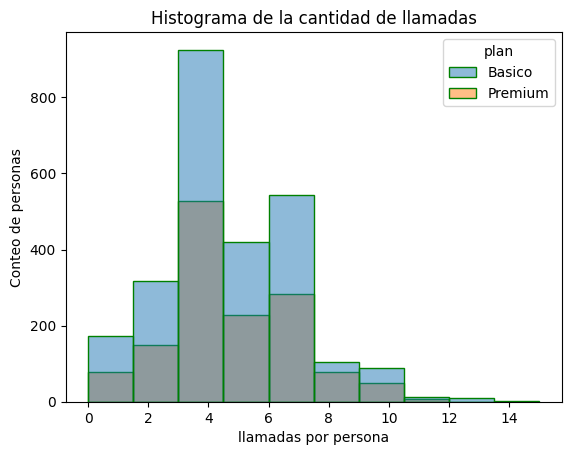

In [32]:
# Histograma para visualizar la cant_llamadas


sns.histplot(data=user_profile, x='cant_llamadas', hue= 'plan', bins= 10,color='skyblue', edgecolor= 'green')
plt.title('Histograma de la cantidad de llamadas')
plt.xlabel('llamadas por persona')
plt.ylabel('Conteo de personas')
plt.show()



💡Insights: 
- La mayoria de las personas hacen pocas llamadas, entre 3 y 7.
- En ambos planes la distribucción se ve muy similar, lo que dice que el tipo de plan no influye en el numero de llamadas que la gente hace.
- La distribucción tiene cola hacía la derecha, solo un grupo pequeño de personas hace mas de 10 llamadas.

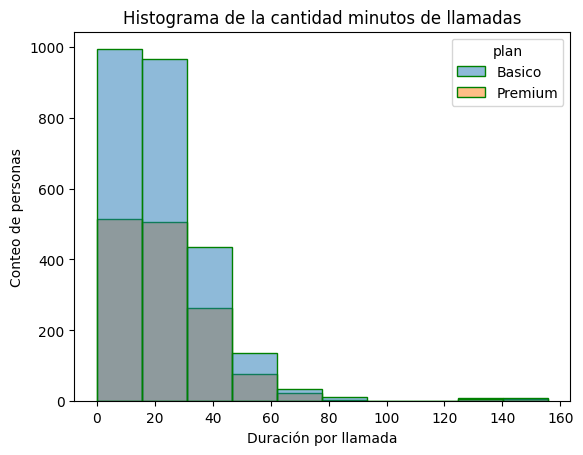

In [33]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(data=user_profile, x='cant_minutos_llamada', hue= 'plan', bins= 10,color='skyblue', edgecolor= 'green')
plt.title('Histograma de la cantidad minutos de llamadas')
plt.xlabel('Duración por llamada')
plt.ylabel('Conteo de personas')
plt.show()




💡Insights: 
- La mayoria de los usuarios hace llamadas cortas, que no pasan de 30min aprox.
- La distribucción muestra una cola hacía la derecha, donde muy pocos usuarios hacen llamadas extendidas de mas de 2 horas.
- Igual aqui como en los demas analisis, el tipo de plan contratado no influye en la duración de las llamadas. Aunque el plan básico sigue teniendo mas cantidad de usuarios.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

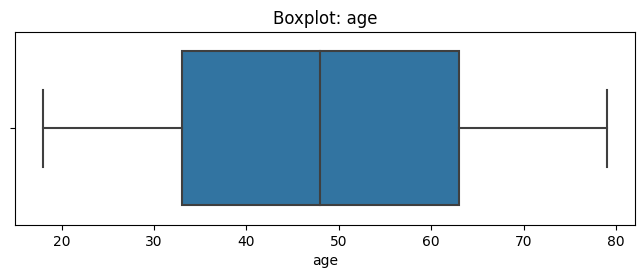

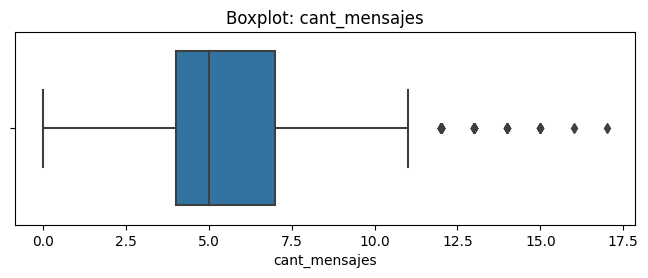

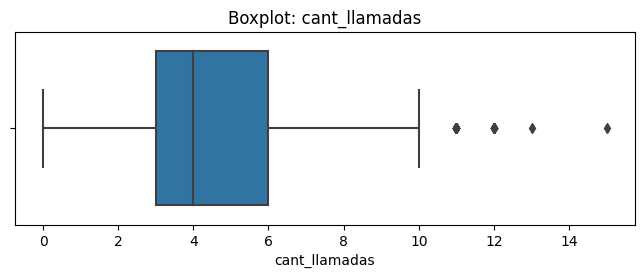

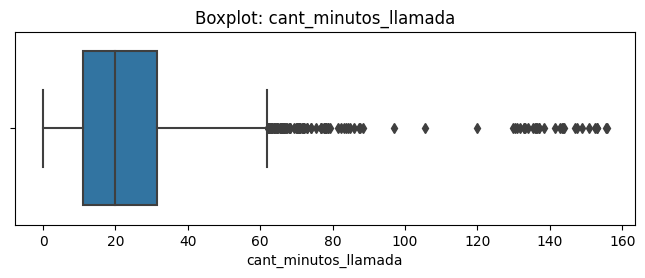

In [34]:
# Visualizando usando BoxPlot 
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

#boxplot por columna
for col in columnas_numericas:
    plt.figure(figsize=(8,2.5))
    sns.boxplot(x=user_profile[col])

    plt.title(f'Boxplot: {col}')
    plt.xlabel(col)

    plt.show()

💡Insights: 
- Age: No hay outliers.
- cant_mensajes: Si existen outliers.
- cant_llamadas: Si existen outliers.
- cant_minutos_llamada: Existen muchos outliers.

No son errores o datos que impidan el analisis, son usuarios con un comportamiento de consumo mas elevado del promedio. Este tipo de datos podría ser util en campañas donde se busquen lineas telefonicas que usen muchos datos y son candidatos a cambio de plan por mas megas.

In [42]:
# Calcular límites con el método IQR
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']


for col in columnas_limites:

    q1 = user_profile[col].quantile(0.25)
    q3 = user_profile[col].quantile(0.75)
    iqr = q3 - q1

    limite_inferior = q1 - 1.5 * iqr
    limite_superior = q3 + 1.5 * iqr

    print(f'\nVariable: {col}')
    print(f'IQR: {iqr:.2f}')
    print(f'Límite inferior: {limite_inferior:.2f}')
    print(f'Límite superior: {limite_superior:.2f}')



Variable: cant_mensajes
IQR: 3.00
Límite inferior: -0.50
Límite superior: 11.50

Variable: cant_llamadas
IQR: 3.00
Límite inferior: -1.50
Límite superior: 10.50

Variable: cant_minutos_llamada
IQR: 20.30
Límite inferior: -19.32
Límite superior: 61.86


In [36]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,3999.000000,3999.000000,3999.000000
mean,5.524381,4.478120,23.317054
std,2.358416,2.144238,18.168095
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.120000
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.415000
max,17.000000,15.000000,155.690000


💡Insights: 

En las tres columnas mantendría los outliers, porque son valores factibles de un negocio de telecomunicaciones. Estos valores representan a clientes con una alta demanda del servicio, lo cual se les puede segmentar para ofrecerles un servicio mas especializado.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [58]:

# Crear columna grupo_uso
def clasificar_uso(length):
    if length['cant_llamadas'] < 5 and length['cant_mensajes'] <5:
        return "Bajo Uso"
    elif length ['cant_llamadas']< 10 and length ['cant_mensajes']<10:
        return "Uso Medio"
    else:
        return "Alto Uso"

user_profile['grupo_uso']=user_profile.apply(clasificar_uso, axis=1)


In [57]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_edad,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Adulto,Uso Medio
1,10001,Mateo,Torres,53.0,NaN,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Adulto,Alto Uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Adulto,Uso Medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Adulto Mayor,Alto Uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Adulto Mayor,Bajo Uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [59]:
# Crear columna grupo_edad
def clasificar_edad(age):
    if age < 30:
        return "Joven"
    elif age < 60:
        return "Adulto"
    else:
        return "Adulto Mayor"

user_profile['grupo_edad']=user_profile['age'].apply(clasificar_edad)

In [46]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Adulto
1,10001,Mateo,Torres,53.0,NaN,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

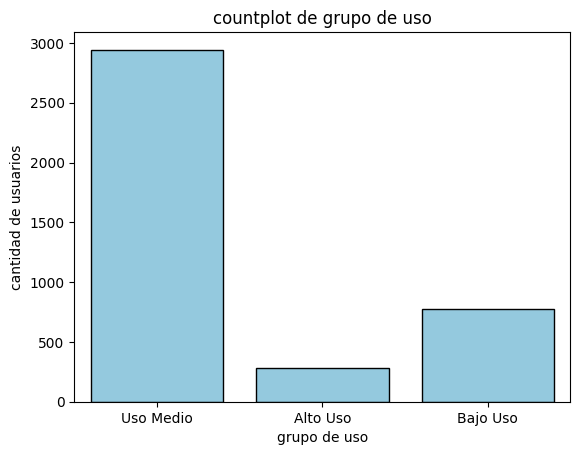

In [60]:

# Visualización de los segmentos por uso

sns.countplot(
    data=user_profile,
    x='grupo_uso',
    color='skyblue',
    edgecolor='black'
)
plt.xlabel('grupo de uso')
plt.ylabel('cantidad de usuarios')
plt.title('countplot de grupo de uso')
plt.show()



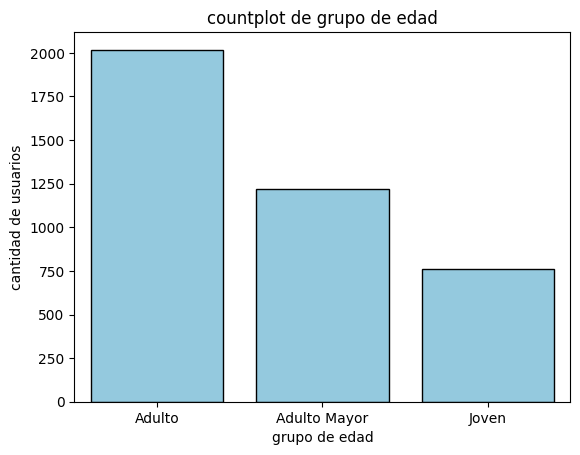

In [61]:
# Visualización de los segmentos por edad
sns.countplot(
    data=user_profile,
    x='grupo_edad',
    color='skyblue',
    edgecolor='black'
)
plt.xlabel('grupo de edad')
plt.ylabel('cantidad de usuarios')
plt.title('countplot de grupo de edad')
plt.show()





---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
- Los resultados reflejan que la mayoría de los problemas no correspondían a errores aleatorios (MCAR), sino a reglas de captura y estructura del propio negocio. Por ejemplo, los valores nulos en "lenght" aparecen porque los mensajes de texto no tienen duración. A continuación se explican todos los hallazgos.

COLUMNA VS PROBLEMA

- City: Valores faltantes y sentinels. Se registran 459 valores nulos.
- Churn_date: Valores nulos en su mayoría de datos: 3534 registros.
- Age: Sentinel inválido (-999).
- Reg_date: Data con fechas futuras (2026). Aprox 40 registros se encontraban fuera de rango (2024).
- Date: Fechas faltantes en 50 registros, que representaba menos del 1% del total de datos.
- Duration: Valores nulos dependen del tipo de evento: 22076 registros.


🔍 **Segmentos por Edad**
- 1er Segmento: Consumo minimo.
        - Nada o casi nulo movimiento de mensajes y llamadas.
        - Consumo de minutos es menor a la mediana.
        - Usuarios de plan básico.
  
- 2do segmento: Consumo moderado
        - Movimiento promedio de mensajes y llamadas.
        - Consumo los pone cerca del comportamiento general (mediana).
        - Son estables.


- 3er segmento: Consumo alto

        - Consumen significativamente mas que el promedio.
        - Representan la minoría del negocio, pero aportan gran valor al ingreso.


  La edad de los clientes se concentra entre los 33 y 63 años, con una mediana de 48 años.

📊 **Segmentos por Nivel de Uso**

Como todo negocio, el cliente que consume mas, genera mas. Los clientes con mayores niveles de llamadas y mensajes representan la mejor oportunidad para monetizar, porque utilizan frecuentemente los servicios (existe una necesidad de por medio), son mas propensos a exceder su límite de datos incluidos y por la misma necesidad, aceptar sin tanto filtro el pagar por tener datos extra o a su vez, cambiar a un plan mas grande. Esto genera ingresos recurrentes. 
Sin embargo, solamente el 35% de los clientes utilizan el servicio Premium, mientras que su mayoría esta en plan básico. Lo cual hace que el reto es mover a clientes del plan básico al premium, sin necesidad de adquirir nuevos clientes.

También es importante conocer las implicaciones que tiene el negocio.
- Existe una demanda para servicios extensos que la oferta actual podría no estar dando abasto.
- Los usuarios de alto consumo pueden generar cargos extras por el uso excesivo y podrían pagarlo, sin embargo no se excenta que provoque una molestia y una baja de servicio.



💡 **Recomendaciones**
1. Diseño de plan "Lite" : Para los usuarios de bajo consumo con riesgo de abandono por sensibilidad al precio, se puede introducir un plan donde la cuota mensual sea menor al plan básico, donde haya tope de limites de minutos incluidos y por ende, menor capacidad de datos. Solo pagas por lo que realmente necesitas y usas.
2. Campañas de Up- Selling: Crear ofertas personalizadas donde puedes introducir descuentos temporales para aumentar tu plan a Premium y podría dar beneficios por el cambio.


---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`

In [ ]:
https://github.com/Andreasaldivar/telecom-analysis-project